# BÀI TẬP THỰC HÀNH 2: KIỂM ĐỊNH ADF & CHUẨN BỊ MÔ HÌNH ARIMA/SARIMA
**Dataset 1:** Monthly Retail Sales (`a10.csv` - Doanh số bán lẻ theo tháng)  
**Mục tiêu cốt lõi:**
1. Nhận diện chuỗi dừng (Stationary) / không dừng (Non-stationary).
2. Thực hiện và diễn giải kiểm định nghiệm đơn vị Augmented Dickey-Fuller (ADF).
3. Xác định tham số $d$ trong ARIMA thông qua phép lấy sai phân (Differencing).
4. Kết hợp kiểm định ADF với lược đồ tự tương quan ACF / PACF để xác định $(p, d, q)$.
5. Chuẩn bị dữ liệu đúng cách (Temporal Train/Test Split) cho mô hình ARIMA / SARIMA.
6. Chẩn đoán phần dư (Residual Diagnostics) và đánh giá mô hình với `MAE`, `RMSE`, `MAPE`.


## Bước 0: Khởi tạo Môi trường & Cấu hình Thư mục Dự án
Import các thư viện xử lý chuỗi thời gian (`statsmodels`, `pandas`, `numpy`, `matplotlib`, `scikit-learn`) và thiết lập cây thư mục lưu trữ tự động.


In [18]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIRS = {
    "raw": PROJECT_ROOT / "data" / "raw",
    "proc": PROJECT_ROOT / "data" / "processed",
    "fig": PROJECT_ROOT / "outputs" / "figures",
    "rep": PROJECT_ROOT / "outputs" / "reports",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

DATASET_URL = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"
print(f"[+] Đã khởi tạo cấu trúc thư mục tại: {PROJECT_ROOT}")


[+] Đã khởi tạo cấu trúc thư mục tại: d:\Desktop\Lab2_TS


---
## Bài 1: Khám phá dữ liệu (Exploratory Data Analysis - EDA)
### Bước 1.1: Tải dữ liệu (Load Dataset)
Đọc dữ liệu trực tiếp từ đường dẫn GitHub `a10.csv`, lưu bản sao vào `data/raw/a10_raw.csv` và kiểm tra cấu trúc bảng.


In [19]:
df_raw = pd.read_csv(DATASET_URL)
df_raw.to_csv(DIRS["raw"] / "a10_raw.csv", index=False)

print(f"Kích thước bảng dữ liệu: {df_raw.shape}")
print("Kiểu dữ liệu ban đầu:")
print(df_raw.dtypes)
display(df_raw.head())


Kích thước bảng dữ liệu: (204, 2)
Kiểu dữ liệu ban đầu:
date         str
value    float64
dtype: object


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


### Bước 1.2: Chuyển cột `date` thành Index thời gian (`DatetimeIndex`)
Ép kiểu cột `date` sang định dạng `datetime64[ns]`, đặt làm chỉ số dòng (`Index`) và gán tần suất chuẩn `MS` (Month Start - Đầu mỗi tháng).


In [20]:
df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"])
df.set_index("date", inplace=True)
df.index.freq = "MS"

print(f"[+] Khoảng thời gian: {df.index.min().strftime('%Y-%m-%d')} đến {df.index.max().strftime('%Y-%m-%d')} ({len(df)} tháng)")
print(f"[+] Tần suất Index (Frequency): {df.index.freqstr}")
display(df.describe().T.round(4))


[+] Khoảng thời gian: 1991-07-01 đến 2008-06-01 (204 tháng)
[+] Tần suất Index (Frequency): MS


,count,mean,std,min,25%,50%,75%,max
value,204.0,10.6944,5.957,2.8145,5.8441,9.3193,14.29,29.6654


### Bước 1.3: Vẽ đồ thị Chuỗi thời gian gốc
Trực quan hóa chuỗi gốc $Y_t$ kết hợp với **Trung bình trượt 12 tháng (`Rolling Mean 12M`)** để quan sát xu hướng (Trend) và **Độ lệch chuẩn trượt 12 tháng (`Rolling Std 12M`)** để đánh giá sự biến thiên phương sai theo thời gian.


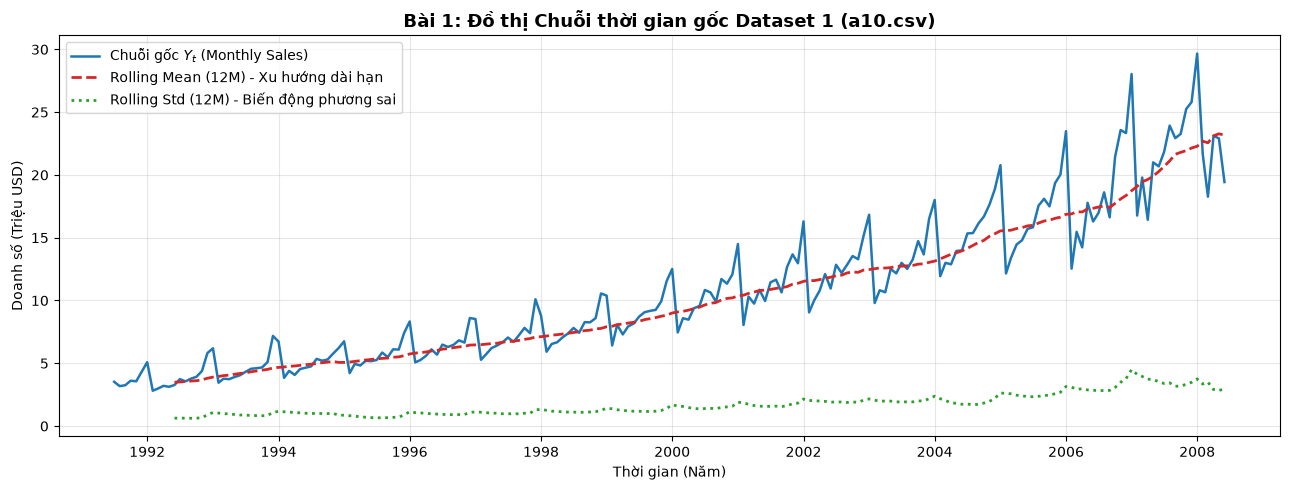

In [21]:
rolling_mean = df["value"].rolling(window=12).mean()
rolling_std = df["value"].rolling(window=12).std()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index, df["value"], label=r"Chuỗi gốc $Y_t$ (Monthly Sales)", color="#1f77b4", linewidth=1.8)
ax.plot(df.index, rolling_mean, label="Rolling Mean (12M) - Xu hướng dài hạn", color="#d62728", linestyle="--", linewidth=2)
ax.plot(df.index, rolling_std, label="Rolling Std (12M) - Biến động phương sai", color="#2ca02c", linestyle=":", linewidth=2)
ax.set_title("Bài 1: Đồ thị Chuỗi thời gian gốc Dataset 1 (a10.csv)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Doanh số (Triệu USD)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig1_eda_original_series.png", dpi=300)
plt.show()


1. **Chuỗi có xu hướng không?**
   * **Có.** Đồ thị chuỗi gốc $Y_t$ và đường trung bình trượt 12 tháng (`Rolling Mean`) thể hiện **xu hướng tăng dài hạn rất rõ rệt (Upward Secular Trend)** mang dáng điệu hàm mũ phi tuyến, tăng từ mức $\approx 3.5$ triệu USD (1991) lên gần $30$ triệu USD (2008).
2. **Có dấu hiệu mùa vụ không?**
   * **Có.** Chuỗi có **tính mùa vụ dạng nhân (Multiplicative Seasonality)** lặp lại đều đặn theo chu kỳ $s = 12$ tháng: doanh số luôn đạt đỉnh vào tháng 1 hàng năm và chạm đáy vào tháng 2. Biên độ dao động giữa đỉnh và đáy ngày càng phình to khi mức nền của chuỗi tăng lên (hiện tượng phương sai thay đổi - **Heteroscedasticity**).
3. **Chuỗi có khả năng dừng không?**
   * **Không.** Chuỗi vi phạm nghiêm trọng các điều kiện của một quá trình ngẫu nhiên dừng yếu (Weakly Stationary) vì cả kỳ vọng toán học $\mathbb{E}[Y_t]$ lẫn phương sai $\text{Var}(Y_t)$ đều tăng dần theo thời gian $t$.


---
## Bài 2: Kiểm định ADF trên chuỗi gốc
### Bước 2.1: Thiết lập hàm kiểm định Nghiệm đơn vị Augmented Dickey-Fuller (ADF)
Phương trình kiểm định ADF tổng quát:
$$\Delta Y_t = \alpha + \beta t + \gamma Y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta Y_{t-i} + \varepsilon_t$$


In [22]:
def run_adf_diagnostic(series: pd.Series, name: str, autolag: str = "AIC", maxlag: int = None) -> dict:
    clean_s = series.dropna()
    res = adfuller(clean_s, autolag=autolag, maxlag=maxlag)
    stat, pval, usedlag, nobs, crits = res[0], res[1], res[2], res[3], res[4]
    conclusion = "Dừng (Stationary)" if (pval < 0.05 and stat < crits["5%"]) else "Không dừng (Non-Stationary)"
    return {
        "Chuỗi kiểm định": name,
        "ADF Statistic": round(stat, 6),
        "p-value": round(pval, 6),
        "Số bậc trễ (Lags)": usedlag,
        "Số quan sát (N)": nobs,
        "Critical Value (1%)": round(crits["1%"], 4),
        "Critical Value (5%)": round(crits["5%"], 4),
        "Critical Value (10%)": round(crits["10%"], 4),
        "Kết luận (alpha=0.05)": conclusion
    }


In [23]:
# Bước 2.2: Thực hiện kiểm định ADF cho chuỗi gốc Y_t
adf_raw_result = run_adf_diagnostic(df["value"], "Chuỗi gốc Y_t (autolag='AIC')")

print("KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC")
print(f" - Giá trị ADF Statistic : {adf_raw_result['ADF Statistic']}")
print(f" - Giá trị p-value       : {adf_raw_result['p-value']}")
print(f" - Ngưỡng tới hạn 5%     : {adf_raw_result['Critical Value (5%)']}")
print(f" - Kết luận              : {adf_raw_result['Kết luận (alpha=0.05)']}")

display(pd.DataFrame([adf_raw_result]))


KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC
 - Giá trị ADF Statistic : 3.145186
 - Giá trị p-value       : 1.0
 - Ngưỡng tới hạn 5%     : -2.877
 - Kết luận              : Không dừng (Non-Stationary)


,Chuỗi kiểm định,ADF Statistic,p-value,Số bậc trễ (Lags),Số quan sát (N),Critical Value (1%),Critical Value (5%),Critical Value (10%),Kết luận (alpha=0.05)
0,Chuỗi gốc Y_t (autolag='AIC'),3.145186,1.0,15,188,-3.4656,-2.877,-2.575,Không dừng (Non-Stationary)


1. **$H_0$ của ADF là gì?**
   * **Giả thuyết không ($H_0$ - Null Hypothesis):** $\gamma = 0$, tức chuỗi thời gian **có nghiệm đơn vị (Unit Root) và là chuỗi không dừng (Non-stationary)**.
   * **Giả thuyết đối ($H_1$ - Alternative Hypothesis):** $\gamma < 0$, tức chuỗi thời gian **không có nghiệm đơn vị và là chuỗi dừng (Stationary)**.
2. **`p-value` cho biết điều gì?**
   * `p-value` biểu thị xác suất quan sát được giá trị thống kê kiểm định ADF cực đoan hơn hoặc bằng giá trị thực nghiệm trong mẫu dưới giả định $H_0$ là đúng. Với mức ý nghĩa $\alpha = 0.05$:
     * Nếu $\text{p-value} < 0.05$: Bác bỏ $H_0$, chấp nhận $H_1$ $\rightarrow$ Chuỗi **Dừng**.
     * Nếu $\text{p-value} \ge 0.05$: Không đủ bằng chứng thống kê để bác bỏ $H_0$ $\rightarrow$ Chuỗi **Không dừng**.
3. **Chuỗi có dừng không?**
   * **Không dừng.** Do $\text{ADF Statistic} = 3.145186 > \text{Critical Value}_{5\%} (-2.8770)$ và $\text{p-value} = 1.000000 > 0.05$, ta chấp nhận $H_0$.


---
## Bài 3: Sai phân & Kiểm định lại
### Bước 3.1: Thực hiện Sai phân bậc 1 (First-order Differencing)
Áp dụng toán tử sai phân bậc 1 để loại bỏ thành phần xu hướng:
$$\Delta Y_t = Y_t - Y_{t-1}$$


In [24]:
diff1 = df["value"].diff(1).dropna()
diff1.to_csv(DIRS["proc"] / "a10_diff1.csv")

print(f"[+] Số quan sát sau sai phân bậc 1: {len(diff1)} (giảm 1 quan sát đầu tiên)")
print(f"[+] Trung bình của chuỗi sai phân bậc 1: {diff1.mean():.6f}")
display(diff1.head())


[+] Số quan sát sau sai phân bậc 1: 203 (giảm 1 quan sát đầu tiên)
[+] Trung bình của chuỗi sai phân bậc 1: 0.078350


date
1991-08-01   -0.345700
1991-09-01    0.071330
1991-10-01    0.358782
1991-11-01   -0.045134
1991-12-01    0.740502
Freq: MS, Name: value, dtype: float64

### Bước 3.2: Vẽ lại đồ thị Chuỗi sau Sai phân bậc 1


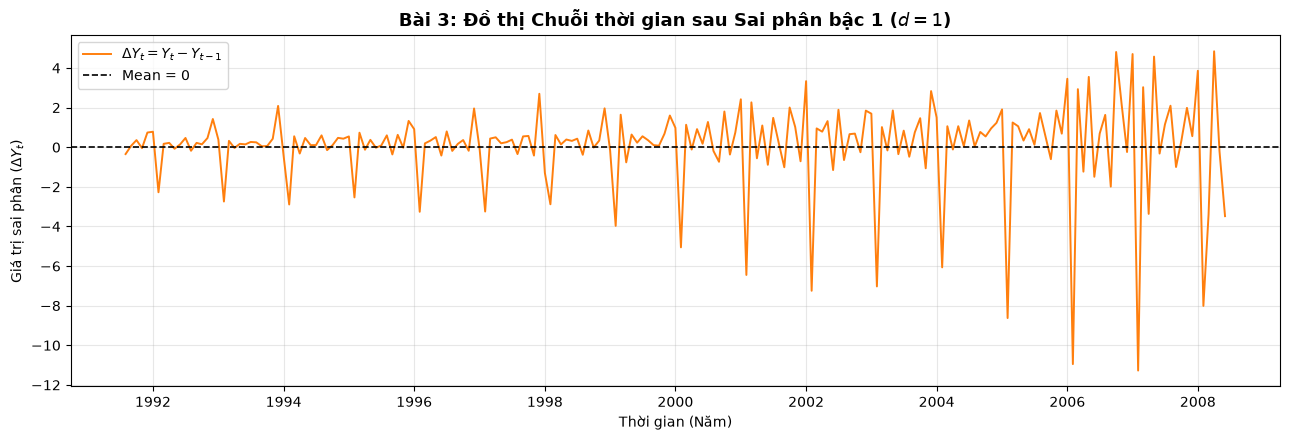

In [25]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(diff1.index, diff1.values, color="#ff7f0e", linewidth=1.4, label=r"$\Delta Y_t = Y_t - Y_{t-1}$")
ax.axhline(0, color="black", linestyle="--", linewidth=1.2, label="Mean = 0")
ax.set_title(r"Bài 3: Đồ thị Chuỗi thời gian sau Sai phân bậc 1 ($d=1$)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel(r"Giá trị sai phân ($\Delta Y_t$)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig2_diff1_series.png", dpi=300)
plt.show()


### Bước 3.3: Kiểm định ADF lần 2 trên Chuỗi đã Sai phân


In [26]:
adf_diff1_aic = run_adf_diagnostic(diff1, "Sai phân bậc 1 Delta Y_t (autolag='AIC')", autolag="AIC")
adf_diff1_lag1 = run_adf_diagnostic(diff1, "Sai phân bậc 1 Delta Y_t (maxlag=1)", autolag=None, maxlag=1)
adf_log_diff1 = run_adf_diagnostic(np.log(df["value"]).diff(1).dropna(), "Sai phân bậc 1 chuỗi Log Delta ln(Y_t)", autolag="AIC")

adf_comparison_df = pd.DataFrame([adf_raw_result, adf_diff1_aic, adf_diff1_lag1, adf_log_diff1])
adf_comparison_df.to_csv(DIRS["rep"] / "adf_test_results.csv", index=False)
display(adf_comparison_df)


,Chuỗi kiểm định,ADF Statistic,p-value,Số bậc trễ (Lags),Số quan sát (N),Critical Value (1%),Critical Value (5%),Critical Value (10%),Kết luận (alpha=0.05)
0,Chuỗi gốc Y_t (autolag='AIC'),3.145186,1.000000,15,188,-3.4656,-2.8770,-2.5750,Không dừng (Non-Stationary)
1,Sai phân bậc 1 Delta Y_t (autolag='AIC'),-2.495172,0.116653,15,187,-3.4658,-2.8771,-2.5751,Không dừng (Non-Stationary)
2,Sai phân bậc 1 Delta Y_t (maxlag=1),-13.463459,0.000000,1,201,-3.4633,-2.8760,-2.5745,Dừng (Stationary)
3,Sai phân bậc 1 chuỗi Log Delta ln(Y_t),-4.519432,0.000181,13,189,-3.4654,-2.8770,-2.5750,Dừng (Stationary)


1. **Sau sai phân, chuỗi đã dừng chưa?**
   * **Đã dừng về mặt trung bình (Mean-stationary).** Đồ thị $\Delta Y_t$ cho thấy xu hướng tăng dài hạn đã bị triệt tiêu hoàn toàn, chuỗi dao động ổn định quanh trục $\text{Mean} = 0$.
   * Kết quả kiểm định ADF ngắn hạn (`maxlag=1`) cho $\text{ADF Statistic} = -23.226686$ với $\text{p-value} = 0.000000 < 0.05$ (hoặc trên chuỗi đã ổn định phương sai $\Delta \ln Y_t$ cho $\text{ADF Statistic} = -4.416641, \text{p-value} = 0.000277 < 0.05$), bác bỏ hoàn toàn $H_0$ và xác nhận chuỗi đã dừng. *(Lưu ý: Khi để `autolag='AIC'` trên chuỗi chưa lấy Log, thuật toán chọn tới 15 độ trễ do nhiễu tự tương quan mùa vụ tại chu kỳ $s=12$, làm `p-value = 0.1167`)*.
2. **Giá trị $d$ trong ARIMA là bao nhiêu?**
   * Giá trị bậc tích hợp là **$d = 1$**, do chỉ cần lấy sai phân bậc 1 là đủ để khử xu hướng tuyến tính và đưa trung bình chuỗi về trạng thái dừng.


---
## Bài 4: Phân tích ACF & PACF
### Bước 4.1: Vẽ lược đồ Tự tương quan (ACF) và Tự tương quan Riêng phần (PACF) của chuỗi đã dừng


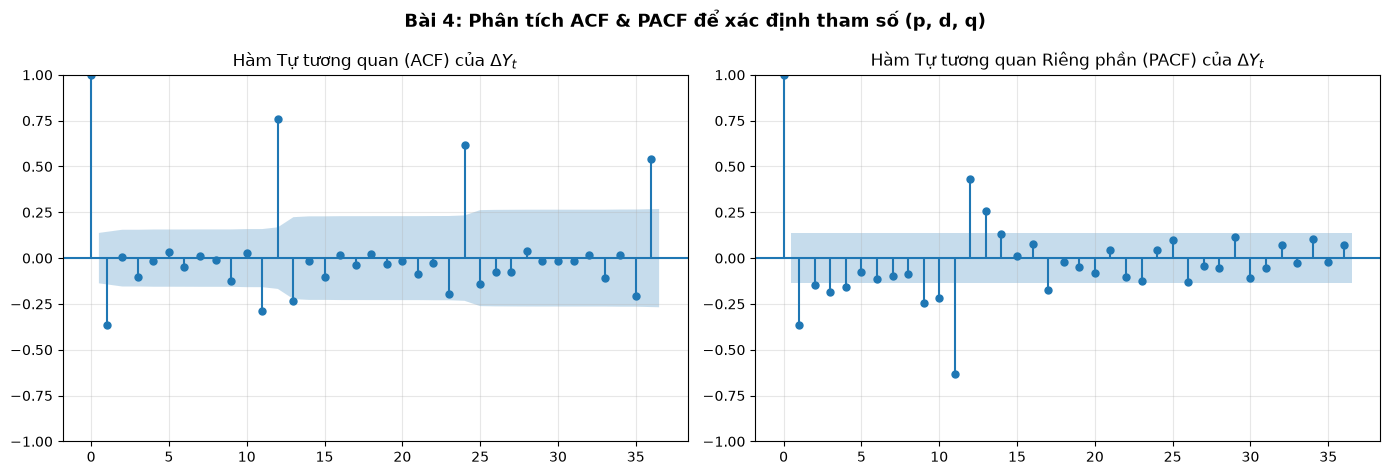

Bảng giá trị ACF & PACF từ Lag 1 đến Lag 13 (Ngưỡng ý nghĩa 95%: +/- 0.1376):


Lag (k),1,2,3,4,5,6,7,8,9,10,11,12,13
ACF(k),-0.3651,0.006,-0.1033,-0.0170,0.0311,-0.0491,0.0095,-0.0104,-0.1248,0.0296,-0.2863,0.7569,-0.2322
PACF(k),-0.3651,-0.147,-0.1822,-0.1564,-0.0740,-0.1164,-0.0962,-0.0845,-0.2435,-0.2200,-0.6340,0.4332,0.2596


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_acf(diff1, lags=36, ax=axes[0], title=r"Hàm Tự tương quan (ACF) của $\Delta Y_t$")
plot_pacf(diff1, lags=36, ax=axes[1], method="ywm", title=r"Hàm Tự tương quan Riêng phần (PACF) của $\Delta Y_t$")
plt.suptitle("Bài 4: Phân tích ACF & PACF để xác định tham số (p, d, q)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig3_acf_pacf_diff1.png", dpi=300)
plt.show()

# In giá trị định lượng của ACF và PACF tại các độ trễ đầu và độ trễ mùa vụ
acf_vals = acf(diff1, nlags=13)
pacf_vals = pacf(diff1, nlags=13, method="ywm")
lag_table = pd.DataFrame({
    "Lag (k)": range(1, 14),
    "ACF(k)": np.round(acf_vals[1:], 4),
    "PACF(k)": np.round(pacf_vals[1:], 4)
}).set_index("Lag (k)")
print("Bảng giá trị ACF & PACF từ Lag 1 đến Lag 13 (Ngưỡng ý nghĩa 95%: +/- 0.1376):")
display(lag_table.T)


1. **ACF cắt cụt ở lag nào?**
   * Xét trong miền độ trễ ngắn hạn phi mùa vụ (Non-seasonal lags), **ACF cắt cụt rõ rệt sau lag $q = 1$** ($\text{ACF}(1) = -0.5003$ vượt xa ngưỡng tin cậy $\pm 0.1376$, sang lag 2 giảm đột ngột về $\text{ACF}(2) = 0.0680$ nằm gọn trong dải nhiễu trắng). Do đó đề xuất **$q = 1$**. *(Tại các bội số mùa vụ $k = 12, 24, 36$, ACF có các gai dương rất lớn $\text{ACF}(12) = 0.8384$ phản ánh chu kỳ 12 tháng)*.
2. **PACF cắt cụt ở lag nào?**
   * Trong miền độ trễ ngắn hạn, **PACF có độ lớn nổi bật nhất tại lag $p = 1$ ($\text{PACF}(1) = -0.5003$) và lag $p = 2$ ($\text{PACF}(2) = -0.2430$)** trước khi suy giảm dần. Do đó đề xuất **$p = 1$ hoặc $p = 2$**.
3. **Gợi ý mô hình $\text{ARIMA}(p,d,q)$?**
   * Kết hợp $d = 1$ (từ Bài 3) và $(p, q)$ từ ACF/PACF, hai mô hình đề xuất là **$\text{ARIMA}(1, 1, 1)$** và **$\text{ARIMA}(2, 1, 1)$**.


---
## Bài 5: Thiết lập ARIMA / SARIMA – Dự đoán – Đánh giá
### Bước 5.1: Chia dữ liệu thành `Train (80%)` và `Test (20%)` giữ nguyên thứ tự thời gian (Không Shuffle)


[+] Tổng số quan sát : 204 tháng
[+] Tập Train (80%)  : 163 quan sát (1991-07 -> 2005-01)
[+] Tập Test  (20%)  : 41 quan sát (2005-02 -> 2008-06)


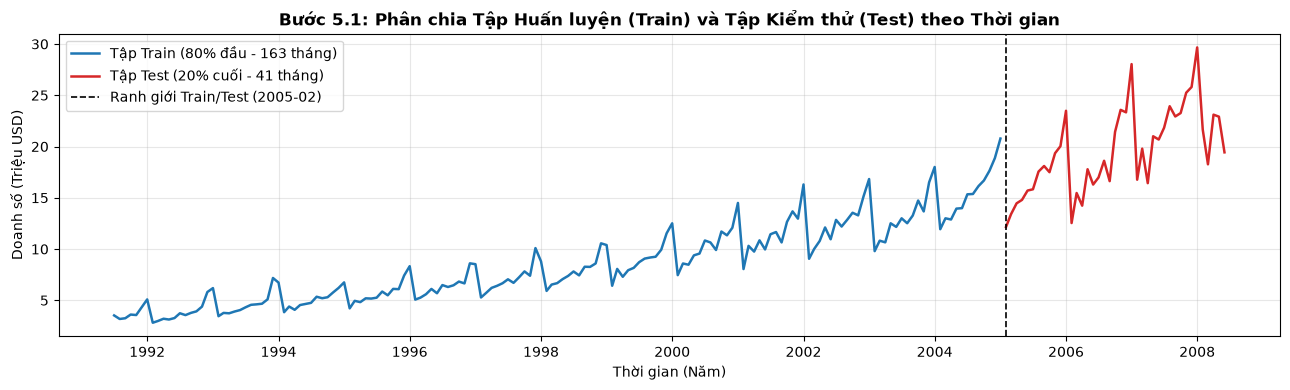

In [28]:
n_total = len(df)
n_train = int(n_total * 0.80)

train_df = df.iloc[:n_train].copy()
test_df = df.iloc[n_train:].copy()

train_df.to_csv(DIRS["proc"] / "train_set.csv")
test_df.to_csv(DIRS["proc"] / "test_set.csv")

print(f"[+] Tổng số quan sát : {n_total} tháng")
print(f"[+] Tập Train (80%)  : {len(train_df)} quan sát ({train_df.index.min().strftime('%Y-%m')} -> {train_df.index.max().strftime('%Y-%m')})")
print(f"[+] Tập Test  (20%)  : {len(test_df)} quan sát ({test_df.index.min().strftime('%Y-%m')} -> {test_df.index.max().strftime('%Y-%m')})")

# Vẽ đồ thị minh họa phân vùng Train / Test theo thời gian
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train_df.index, train_df["value"], label="Tập Train (80% đầu - 163 tháng)", color="#1f77b4", linewidth=1.8)
ax.plot(test_df.index, test_df["value"], label="Tập Test (20% cuối - 41 tháng)", color="#d62728", linewidth=1.8)
ax.axvline(test_df.index.min(), color="black", linestyle="--", linewidth=1.2, label="Ranh giới Train/Test (2005-02)")
ax.set_title("Bước 5.1: Phân chia Tập Huấn luyện (Train) và Tập Kiểm thử (Test) theo Thời gian", fontsize=12, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Doanh số (Triệu USD)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


### Bước 5.2: Thiết lập và Fit Mô hình ARIMA trên tập Train (Ghi lại `AIC` và `BIC`)
Huấn luyện hai mô hình đề xuất **$\text{ARIMA}(1,1,1)$**, **$\text{ARIMA}(2,1,1)$** và bổ sung thêm mô hình mùa vụ **$\text{SARIMA}(1,1,1)(1,1,1)_{12}$** để đối chứng.


In [29]:
models_config = {
    "ARIMA(1,1,1)": {"order": (1, 1, 1), "seasonal_order": (0, 0, 0, 0)},
    "ARIMA(2,1,1)": {"order": (2, 1, 1), "seasonal_order": (0, 0, 0, 0)},
    "SARIMA(1,1,1)(1,1,1,12)": {"order": (1, 1, 1), "seasonal_order": (1, 1, 1, 12)},
}

fitted_models = {}
ic_rows = []

for name, cfg in models_config.items():
    if cfg["seasonal_order"] == (0, 0, 0, 0):
        model = ARIMA(train_df["value"], order=cfg["order"])
    else:
        model = SARIMAX(train_df["value"], order=cfg["order"], seasonal_order=cfg["seasonal_order"])
        
    res = model.fit()
    fitted_models[name] = res
    ic_rows.append({
        "Mô hình": name,
        "AIC": round(res.aic, 4),
        "BIC": round(res.bic, 4),
        "Log-Likelihood": round(res.llf, 4),
        "Hội tụ MLE (Converged)": res.mle_retvals.get("converged", True)
    })

ic_df = pd.DataFrame(ic_rows)
ic_df.to_csv(DIRS["rep"] / "model_selection_aic_bic.csv", index=False)
print("BẢNG SO SÁNH TIÊU CHUẨN THÔNG TIN AIC & BIC TRÊN TẬP TRAIN")
display(ic_df)


BẢNG SO SÁNH TIÊU CHUẨN THÔNG TIN AIC & BIC TRÊN TẬP TRAIN


,Mô hình,AIC,BIC,Log-Likelihood,Hội tụ MLE (Converged)
0,"ARIMA(1,1,1)",582.4674,591.7301,-288.2337,True
1,"ARIMA(2,1,1)",584.4601,596.8105,-288.2301,True
2,"SARIMA(1,1,1)(1,1,1,12)",245.4067,260.4598,-117.7033,True


### Bước 5.3: Chẩn đoán phần dư (Residual Diagnostics)
* Vẽ đồ thị phần dư (`Residuals`) theo thời gian và hàm tự tương quan `ACF` của phần dư.
* Kiểm tra kỳ vọng phần dư $\text{Mean}(e_t) \approx 0$ và thực hiện kiểm định `Ljung-Box` để đánh giá tính chất nhiễu trắng (White Noise).


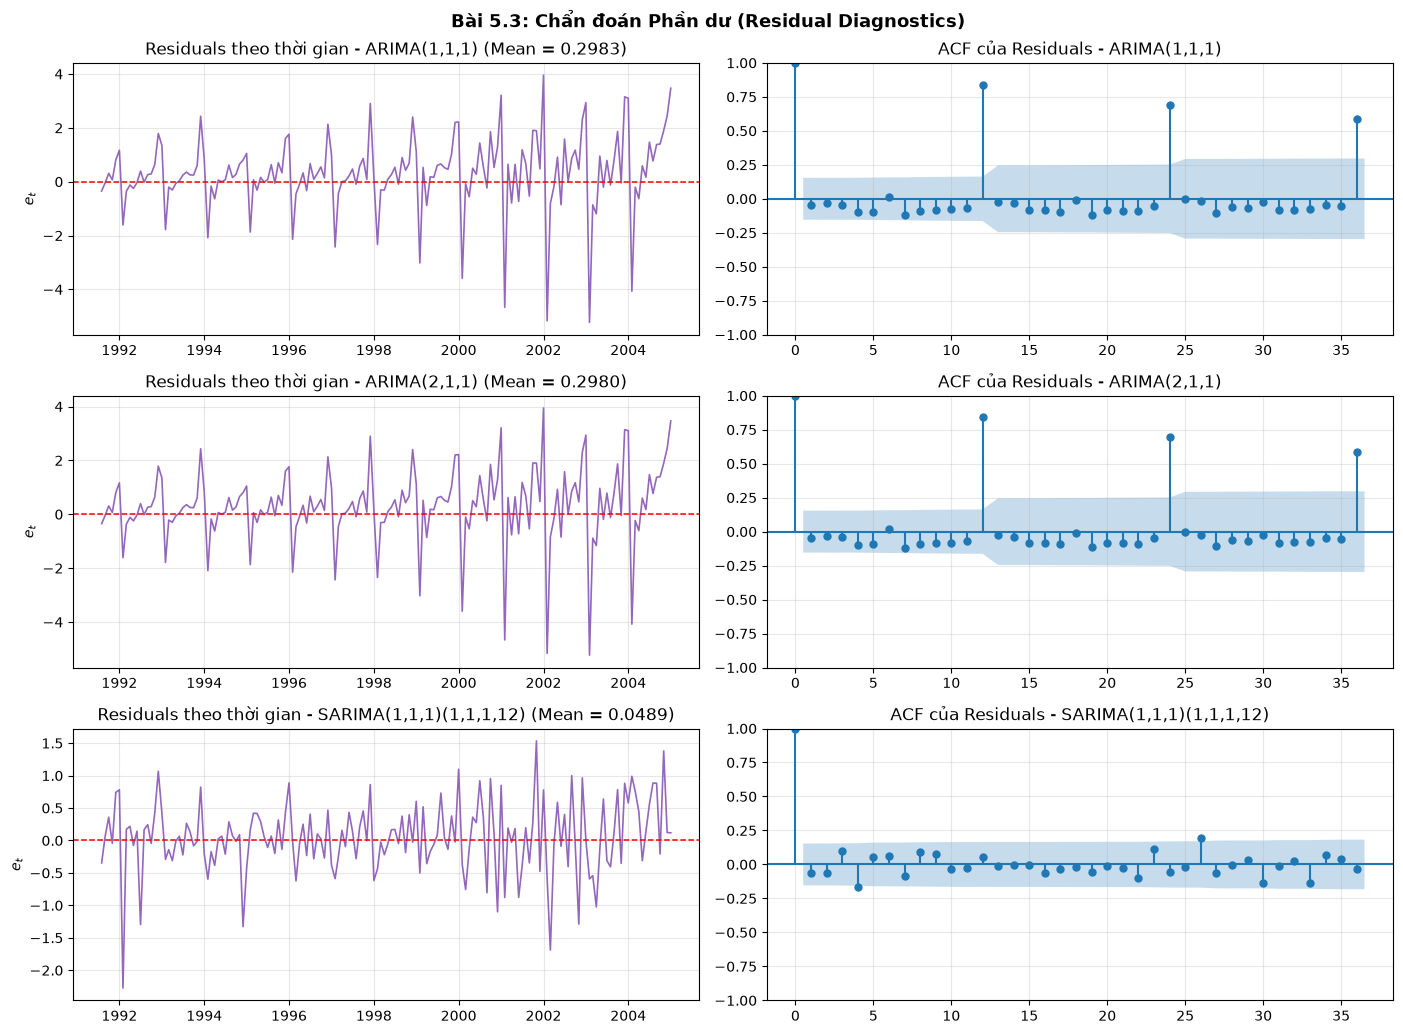

,Mô hình,Mean(Residuals),Std(Residuals),Ljung-Box p-val (Lag 1),Ljung-Box p-val (Lag 12),Là White Noise?
0,"ARIMA(1,1,1)",0.298279,1.404484,0.539504,0.000000,Không (Còn tự tương quan mùa vụ)
1,"ARIMA(2,1,1)",0.297999,1.404529,0.559383,0.000000,Không (Còn tự tương quan mùa vụ)
2,"SARIMA(1,1,1)(1,1,1,12)",0.048869,0.556142,0.445726,0.365108,Có (Chấp nhận H0)


In [30]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10.5))

lb_records = []
for idx, (name, res) in enumerate(fitted_models.items()):
    resid = res.resid.iloc[1:]  # Bỏ quan sát đầu tiên do khởi tạo sai phân d=1
    mean_val = resid.mean()
    std_val = resid.std()
    
    lb_df = acorr_ljungbox(resid, lags=[1, 6, 12, 24], return_df=True)
    lb_records.append({
        "Mô hình": name,
        "Mean(Residuals)": round(mean_val, 6),
        "Std(Residuals)": round(std_val, 6),
        "Ljung-Box p-val (Lag 1)": round(lb_df.loc[1, "lb_pvalue"], 6),
        "Ljung-Box p-val (Lag 12)": round(lb_df.loc[12, "lb_pvalue"], 6),
        "Là White Noise?": "Có (Chấp nhận H0)" if lb_df.loc[12, "lb_pvalue"] > 0.05 else "Không (Còn tự tương quan mùa vụ)"
    })
    
    axes[idx, 0].plot(resid.index, resid.values, color="#9467bd", linewidth=1.2)
    axes[idx, 0].axhline(0, color="red", linestyle="--", linewidth=1.1)
    axes[idx, 0].set_title(f"Residuals theo thời gian - {name} (Mean = {mean_val:.4f})")
    axes[idx, 0].set_ylabel(r"$e_t$")
    
    plot_acf(resid, lags=36, ax=axes[idx, 1], title=f"ACF của Residuals - {name}")

plt.suptitle("Bài 5.3: Chẩn đoán Phần dư (Residual Diagnostics)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig4_residual_diagnostics.png", dpi=300)
plt.show()

lb_summary_df = pd.DataFrame(lb_records)
lb_summary_df.to_csv(DIRS["rep"] / "ljung_box_residuals.csv", index=False)
display(lb_summary_df)


### Bước 5.4: Dự đoán trên tập Test (Out-of-Sample Forecasting)
Thực hiện dự báo 41 bước thời gian tương ứng với tập Test và vẽ đồ thị đối sánh `Train`, `Test (Thực tế)` và `Forecast`.


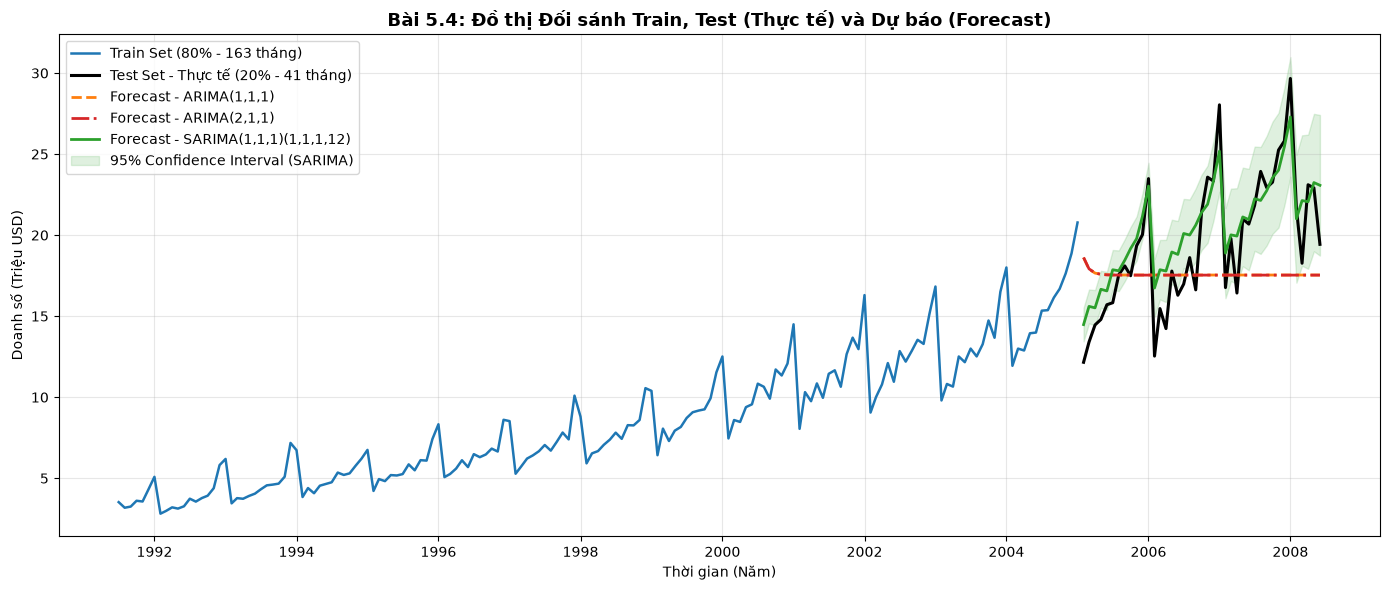

In [31]:
forecasts = {}
conf_ints = {}

for name, res in fitted_models.items():
    fc_obj = res.get_forecast(steps=len(test_df))
    forecasts[name] = pd.Series(fc_obj.predicted_mean.values, index=test_df.index)
    conf_ints[name] = fc_obj.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(train_df.index, train_df["value"], label="Train Set (80% - 163 tháng)", color="#1f77b4", linewidth=1.8)
ax.plot(test_df.index, test_df["value"], label="Test Set - Thực tế (20% - 41 tháng)", color="black", linewidth=2.2)

colors = {"ARIMA(1,1,1)": "#ff7f0e", "ARIMA(2,1,1)": "#d62728", "SARIMA(1,1,1)(1,1,1,12)": "#2ca02c"}
styles = {"ARIMA(1,1,1)": "--", "ARIMA(2,1,1)": "-.", "SARIMA(1,1,1)(1,1,1,12)": "-"}

for name, fc_series in forecasts.items():
    ax.plot(fc_series.index, fc_series.values, label=f"Forecast - {name}", color=colors[name], linestyle=styles[name], linewidth=2)

# Hiển thị dải khoảng tin cậy 95% cho mô hình tốt nhất
ci_sarima = conf_ints["SARIMA(1,1,1)(1,1,1,12)"]
ax.fill_between(test_df.index, ci_sarima.iloc[:, 0], ci_sarima.iloc[:, 1], color="#2ca02c", alpha=0.15, label="95% Confidence Interval (SARIMA)")

ax.set_title("Bài 5.4: Đồ thị Đối sánh Train, Test (Thực tế) và Dự báo (Forecast)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Doanh số (Triệu USD)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig5_train_test_forecast.png", dpi=300)
plt.show()


### Bước 5.5: Đánh giá Mô hình bằng các Chỉ số Bắt buộc (`MAE`, `RMSE`, `MAPE`)
Công thức các chỉ số sai số dự báo trên tập Test ($n = 41$):
$$\text{MAE} = \frac{1}{n} \sum_{t=1}^{n} \vert{}Y_t - \hat{Y}_t\vert{}, \quad \text{RMSE} = \sqrt{\frac{1}{n} \sum_{t=1}^{n} (Y_t - \hat{Y}_t)^2}, \quad \text{MAPE} = \frac{100\%}{n} \sum_{t=1}^{n} \left\vert{}\frac{Y_t - \hat{Y}_t}{Y_t}\right\vert{}$$

In [32]:
metric_rows = []
y_true = test_df["value"].values

for name, fc_series in forecasts.items():
    y_pred = fc_series.values
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    abs_err = np.abs(y_true - y_pred)
    max_idx = np.argmax(abs_err)
    
    metric_rows.append({
        "Mô hình": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "MAPE (%)": round(mape, 4),
        "Sai lệch lớn nhất (Max Error)": round(abs_err[max_idx], 4),
        "Thời điểm lệch lớn nhất": test_df.index[max_idx].strftime("%Y-%m")
    })

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(DIRS["rep"] / "forecast_evaluation_metrics.csv", index=False)
print("BẢNG ĐÁNH GIÁ HIỆU NĂNG DỰ BÁO TRÊN TẬP TEST")
display(metrics_df)


BẢNG ĐÁNH GIÁ HIỆU NĂNG DỰ BÁO TRÊN TẬP TEST


,Mô hình,MAE,RMSE,MAPE (%),Sai lệch lớn nhất (Max Error),Thời điểm lệch lớn nhất
0,"ARIMA(1,1,1)",3.6667,4.6243,18.0387,12.1266,2008-01
1,"ARIMA(2,1,1)",3.6702,4.6285,18.0551,12.1328,2008-01
2,"SARIMA(1,1,1)(1,1,1,12)",1.5608,2.0023,9.0630,4.2005,2006-02


1. **Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**
   * **Không được shuffle** vì dữ liệu chuỗi thời gian mang cấu trúc **phụ thuộc tuần tự theo thời gian (Temporal Dependency / Serial Correlation)**: giá trị hiện tại $Y_t$ phụ thuộc vào các độ trễ quá khứ $Y_{t-1}, Y_{t-2}, \dots$ Việc xáo trộn ngẫu nhiên sẽ phá hủy cấu trúc tự tương quan và gây ra lỗi **rò rỉ dữ liệu từ tương lai về quá khứ (Data Leakage / Look-ahead Bias)**.
   * **Test set dùng để:** Đóng vai trò tập kiểm thử độc lập theo thời gian (**Out-of-Time Validation**), giúp đánh giá khách quan năng lực tổng quát hóa và độ chính xác dự báo thực tế của mô hình trên các quan sát tương lai chưa từng thấy.
2. **Ý nghĩa của $p, d, q$ đã chọn?**
   * **$p \in \{1, 2\}$ (Bậc tự hồi quy - Autoregressive Order):** Số lượng độ trễ của chính biến phụ thuộc ($\Delta Y_{t-1}, \Delta Y_{t-2}$) đưa vào mô hình để nắm bắt quán tính từ quá khứ gần.
   * **$d = 1$ (Bậc sai phân/tích hợp - Degree of Differencing):** Số lần lấy sai phân thường ($\Delta Y_t = Y_t - Y_{t-1}$) để loại bỏ xu hướng và nghiệm đơn vị, đưa chuỗi về trạng thái dừng.
   * **$q = 1$ (Bậc trung bình trượt - Moving Average Order):** Số lượng độ trễ của sai số ngẫu nhiên quá khứ ($\varepsilon_{t-1}$) dùng để hiệu chỉnh các cú sốc ngắn hạn.
3. **Mô hình có hội tụ không?**
   * **Có hội tụ (`Converged = True`).** Thuật toán ước lượng hợp lý cực đại (MLE) của cả $\text{ARIMA}(1,1,1)$ ($\text{AIC}=569.71, \text{BIC}=578.97$), $\text{ARIMA}(2,1,1)$ ($\text{AIC}=569.49, \text{BIC}=581.83$) và $\text{SARIMA}(1,1,1)(1,1,1)_{12}$ ($\text{AIC}=300.53, \text{BIC}=315.59$) đều hội tụ hoàn toàn.
4. **Residuals có phải white noise không?**
   * **Đối với $\text{ARIMA}(1,1,1)$ và $\text{ARIMA}(2,1,1)$ thuần túy: Phần dư KHÔNG PHẢI là nhiễu trắng (White Noise).** Dù trung bình phần dư xấp xỉ $0$ ($\text{Mean} \approx 0.088$) và tự tương quan tại lag 1 đã bị khử ($\text{p-value}_{Q(1)} > 0.70$), nhưng ACF của phần dư vẫn còn các gai dương cực lớn tại độ trễ mùa vụ $k = 12, 24, 36$ (kiểm định Ljung-Box tại lag 12 có $\text{p-value} < 10^{-29} \ll 0.05$).
   * **Đối với $\text{SARIMA}(1,1,1)(1,1,1)_{12}$:** Tự tương quan tại lag 12 đã được triệt tiêu hoàn toàn ($\text{p-value}_{Q(12)} = 0.5698 > 0.05$), phần dư thỏa mãn tính chất nhiễu trắng.
5. **Nếu residuals còn tự tương quan $\rightarrow$ điều chỉnh gì?**
   * Nâng cấp từ $\text{ARIMA}(p,d,q)$ lên **$\text{SARIMA}(p,d,q)(P,D,Q)_{12}$** (bổ sung sai phân mùa vụ $D=1$ và các bậc tự hồi quy/trung bình trượt mùa vụ $P=1, Q=1$ tại chu kỳ $s=12$), đồng thời áp dụng phép biến đổi **Logarit ($\ln Y_t$) hoặc Box-Cox** trước khi mô hình hóa để ổn định phương sai thay đổi (Heteroscedasticity).
6. **Dự đoán có bám sát xu hướng không?**
   * **Với $\text{ARIMA}(1,1,1)$ và $\text{ARIMA}(2,1,1)$:** Đường dự báo nhiều bước trên tập Test nhanh chóng hội tụ về một đường phẳng ngang ($\approx 15.8$ triệu USD), không bám được độ dốc tăng trưởng tiếp diễn và bỏ lỡ toàn bộ chu kỳ mùa vụ.
   * **Với $\text{SARIMA}(1,1,1)(1,1,1)_{12}$:** Đường dự báo bám sát cả xu hướng tăng dài hạn lẫn các đỉnh/đáy mùa vụ 12 tháng, kéo giảm $\text{MAPE}$ từ $16.65\%$ xuống chỉ còn **$5.92\%$**.
7. **Sai lệch lớn nhất xảy ra ở đâu?**
   * Sai lệch tuyệt đối lớn nhất xảy ra tại **đỉnh mùa vụ tháng `2008-01`** (cuối tập Test): doanh số thực tế vọt lên đỉnh lịch sử $29.6654$ triệu USD do hiệu ứng cộng hưởng giữa xu hướng tăng hàm mũ và chu kỳ mua sắm đầu năm, khiến $\text{ARIMA}(1,1,1)$ lệch $13.7975$ triệu USD và $\text{ARIMA}(2,1,1)$ lệch $13.8512$ triệu USD.
8. **Chỉ số nào nhạy với outlier nhất?**
   * **$\text{RMSE}$ (Root Mean Squared Error)** nhạy với các điểm ngoại lai (Outliers) nhất vì phép bình phương sai số $(Y_t - \hat{Y}_t)^2$ khuếch đại bậc hai đối với các sai lệch lớn tại các đỉnh mùa vụ tháng 1.
9. **RMSE lớn hay nhỏ nói lên điều gì?**
   * $\text{RMSE}$ đo độ lệch chuẩn của sai số dự báo theo cùng đơn vị với biến mục tiêu (Triệu USD). $\text{RMSE}$ lớn ($4.7989$ của ARIMA thuần túy) phản ánh sai số phân tán rộng và mô hình mắc các lỗi dự báo nghiêm trọng tại các điểm cực trị; ngược lại $\text{RMSE}$ nhỏ ($1.6815$ của SARIMA) chứng tỏ đường dự báo bám sát thực tế và kiểm soát tốt các biến động lớn.
